# Preprocesamiento del Dataset
Este Notebook se ha generado para realizar la carga y limpieza del Dataset que se utilizará para hacer un modelo de predicción de diabetes.

## 1) Carga y muestra del Dataset

En esta primera parte se recupera el dataset descargado y se presenta una muestra de la información que compone el Dataset.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

PATH = '../data/diabetes_prediction_dataset.csv'

diabetes_ds = pd.read_csv(PATH)
display(diabetes_ds.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 2) Estadísticas del Dataset.
Se presentan las estadísitcas con referencia a la cantidad de valores nulos que componen el dataset en cada uno de sus campos, así como los valores duplicados del mismo.

In [2]:
def load_statistics_data_set(data: pd.DataFrame):
    display(data.describe())
    statistics_null_values = data.isnull().sum()
    print('Registros con datos nulos:')
    display(statistics_null_values)
    statistics_duplicate_values = data.duplicated().sum()
    print(f'Registros con datos duplicados: {statistics_duplicate_values}')
    print(f"Registros totales: {len(data)}")


load_statistics_data_set(diabetes_ds)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


Registros con datos nulos:


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Registros con datos duplicados: 3854
Registros totales: 100000


## 3) Limpieza del Dataset
Se realizará la normalización de los campos, codificando valores de tipo cadena a números para posteriormente realizar el borrado de duplicados y los registros con valores nulos.

In [3]:
#Codificar valores de género
display(diabetes_ds.groupby('gender').count())
diabetes_ds['gender_value'] = diabetes_ds['gender'].map({'Male': 0, 'Female': 1, 'Other': 2})
diabetes_ds.drop('gender', axis=1, inplace=True)
display(diabetes_ds.head())

#Codificar valores de smoking_history
display(diabetes_ds.groupby(['smoking_history']).count())
diabetes_ds['smoking_history_val'] = diabetes_ds['smoking_history'].map(
    {'No Info': 0, 'current': 1, 'ever': 2, 'former': 3, 'never': 4, 'not current': 5})
diabetes_ds.drop(['smoking_history'], axis=1, inplace=True)
display(diabetes_ds.head())

#Borrado de nulos y duplicados
print(f"Numero de registros antes de limpieza: {len(diabetes_ds)}")
diabetes_ds.dropna(inplace=True)
diabetes_ds.drop_duplicates(inplace=True)
print(f"Numero de registros final: {len(diabetes_ds)}")


,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
gender,,,,,,,,
Female,58552,58552,58552,58552,58552,58552,58552,58552
Male,41430,41430,41430,41430,41430,41430,41430,41430
Other,18,18,18,18,18,18,18,18


,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_value
0,80.0,0,1,never,25.19,6.6,140,0,1
1,54.0,0,0,No Info,27.32,6.6,80,0,1
2,28.0,0,0,never,27.32,5.7,158,0,0
3,36.0,0,0,current,23.45,5.0,155,0,1
4,76.0,1,1,current,20.14,4.8,155,0,0


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_value
smoking_history,,,,,,,,
No Info,35816,35816,35816,35816,35816,35816,35816,35816
current,9286,9286,9286,9286,9286,9286,9286,9286
ever,4004,4004,4004,4004,4004,4004,4004,4004
former,9352,9352,9352,9352,9352,9352,9352,9352
never,35095,35095,35095,35095,35095,35095,35095,35095
not current,6447,6447,6447,6447,6447,6447,6447,6447


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_value,smoking_history_val
0,80.0,0,1,25.19,6.6,140,0,1,4
1,54.0,0,0,27.32,6.6,80,0,1,0
2,28.0,0,0,27.32,5.7,158,0,0,4
3,36.0,0,0,23.45,5.0,155,0,1,1
4,76.0,1,1,20.14,4.8,155,0,0,1


Numero de registros antes de limpieza: 100000
Numero de registros final: 96146


## 4) Presentación del valor a predecir con respecto al Dataset.
Se presenta la distribución de los valores entre los pacientes diabéticos y no diabéticos así como una muestra del dataset limpio.

<Axes: title={'center': 'Diabetes'}, xlabel='diabetes'>

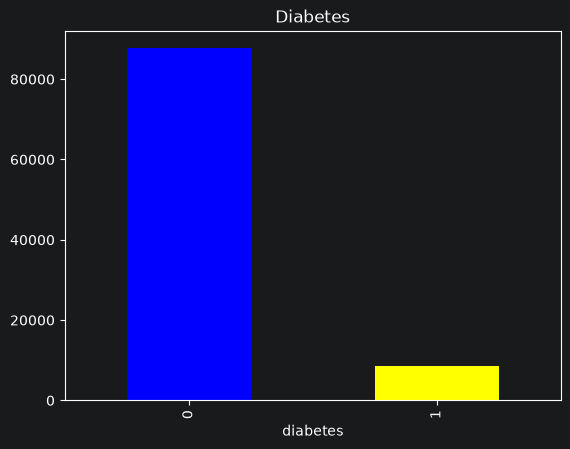

In [4]:
diabetes_ds['diabetes'].value_counts().plot(kind='bar', color=['blue', 'yellow'], title='Diabetes', ax=plt.gca())

In [5]:
#Muestra
diabetes_ds.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_value,smoking_history_val
0,80.0,0,1,25.19,6.6,140,0,1,4
1,54.0,0,0,27.32,6.6,80,0,1,0
2,28.0,0,0,27.32,5.7,158,0,0,4
3,36.0,0,0,23.45,5.0,155,0,1,1
4,76.0,1,1,20.14,4.8,155,0,0,1


## 5) Guardado del Dataset limpio.

In [6]:
diabetes_ds.to_csv('../data/diabetes_prediction_dataset_clean.csv')
